# DeepShape2, part 2: deconvolve → deblend → measure shapes

Part 1 ended with, for every bright galaxy, a **dirty facet** (128×128, blurred by the telescope, noisy, neighbours included) and
its **PSF**, plus the answer key: the true shape (e1, e2) and an **isolated stamp** of each galaxy alone.

This notebook does what DeepShape2 does next, one step at a time:

| Step | What it fixes | Repo function / model | Weights file |
|---|---|---|---|
| 1. Measure a shape | (the ruler we use throughout) | `shape_galsim` (GalSim adaptive moments) | none |
| 2. Deconvolve | the PSF blur and the noise | `reconstruct_facets` → **HQS-PnP** with a **DRUNet** denoiser | `drunet_blended.pt` |
| 3. Deblend | light from neighbouring galaxies | `reconstruct_facets(..., deblender=...)` → **VAE** | `vae_mha.pt` |
| 4. Measure shapes with a network | what's left of the PSF's effect and the noise | `predict_shape` → **shapenet_full** | `shape_network_full.pt`, `eq_block.pt`, `autoencoder_jit.pt` |

Steps 2 and 3 are what `scripts/implementation/reconstruction.py` does. Step 4 is how `shape_measurement/training_full.py`
makes its predictions, and the comparison at the end follows `scripts/implementation/shape_measurement.py`.

**Before running:** run part 1 to the end; its last cell writes `part1_facets.npz`, which this notebook reads.
**Kernel:** the `deepshape` conda env. Runs in about 2 minutes on a Mac.

## 0. Setup

Same macOS import-order workaround as in part 1. The networks run fastest on the Mac's GPU, which PyTorch calls `"mps"`.

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import numpy as np
np.linalg.norm(np.ones(2))   # macOS: wake up numpy's maths library before torch loads
import torch
import galsim

import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore")
%matplotlib inline
plt.rcParams["figure.dpi"] = 110

DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
print("networks will run on:", DEVICE)


def show(ax, img, title, cmap="inferno", **kw):
    ax.imshow(img, origin="lower", cmap=cmap, **kw)
    ax.set_title(title, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

networks will run on: mps


### Load part 1's results and the config

`load_model` normally looks for weights in the config's `MODEL_DIR`, which points at the cluster. On this laptop the weights are in
`deepshape2/DS2_model_weights/`, so we always pass the path explicitly.

In [2]:
from deepshape2.utils import load_config

cfg = load_config()
WEIGHTS = Path("..") / "deepshape2" / "DS2_model_weights"
for name in ["drunet_blended.pt", "vae_mha.pt", "shape_network_full.pt", "eq_block.pt", "autoencoder_jit.pt"]:
    print(f"{name:25s}", "found" if (WEIGHTS / name).exists() else "MISSING")

data = np.load("part1_facets.npz")
dirty, psf = data["dirty"], data["psf"]
isolated, blended = data["isolated_stamps"], data["blended_stamps"]
peaks, noise_rms = data["peaks"], float(data["noise_rms"])

# One row per galaxy, in the same order as the image arrays
gal = pd.DataFrame({c: data[c] for c in ["flux", "size", "e1", "e2"]}, index=data["galaxy_id"])
gal["flux [µJy]"] = gal["flux"] * 1e6
gal["S/N"] = peaks / noise_rms
e_true = gal[["e1", "e2"]].values

# The selection scripts/implementation/shape_measurement.py uses to judge results (explained in section 5c):
# bright enough (> 50 µJy) and clearly visible in the dirty image (peak > 3 x the 0.71 µJy noise).
selected = (gal["flux"].values > 50e-6) & (peaks > 3 * 0.71e-6)

i_target = list(gal.index).index(int(data["target"]))
i_neighbour = list(gal.index).index(int(data["neighbour"]))

print(f"\n{len(gal)} galaxies, facets {dirty.shape}, noise {noise_rms * 1e6:.2f} µJy/beam, {selected.sum()} pass the selection")

drunet_blended.pt         found
vae_mha.pt                found
shape_network_full.pt     found
eq_block.pt               found
autoencoder_jit.pt        found

46 galaxies, facets (46, 128, 128), noise 0.71 µJy/beam, 20 pass the selection


## 1. What we're measuring, and the ruler we measure it with

### Ellipticity (e1, e2)

An ellipse with long axis *a*, short axis *b*, tilted by an angle θ has

$$|e| = \frac{a^2 - b^2}{a^2 + b^2}, \qquad e_1 = |e|\cos 2\theta, \qquad e_2 = |e|\sin 2\theta$$

So **e1** says "stretched along x (+) or along y (−)", and **e2** says the same for the two diagonals. The angle is doubled
because an ellipse turned by 180° is the same ellipse.

Why care so much: weak lensing changes galaxy shapes by only **a few percent** (shear ~0.01–0.05), while galaxies' own shapes
scatter by ~0.25. So lensing is only visible by averaging over huge numbers of galaxies, and a method that measures every shape
slightly wrong *in the same direction* (a **bias**) is much worse than one that is merely noisy.

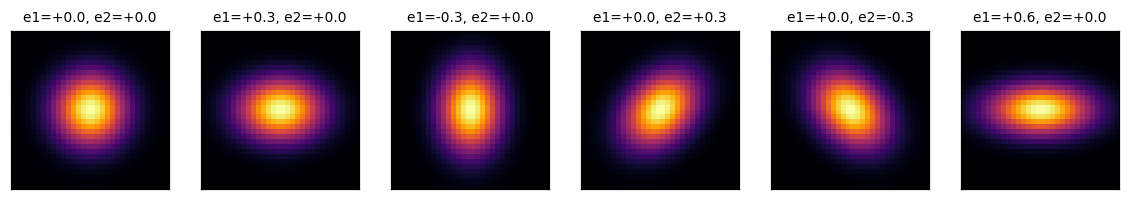

In [3]:
examples = [(0, 0), (0.3, 0), (-0.3, 0), (0, 0.3), (0, -0.3), (0.6, 0)]
fig, ax = plt.subplots(1, len(examples), figsize=(13, 2.4))
for a, (e1, e2) in zip(ax, examples):
    img = galsim.Gaussian(sigma=1.0).shear(e1=e1, e2=e2).drawImage(nx=32, ny=32, scale=0.2).array
    show(a, img, f"e1={e1:+.1f}, e2={e2:+.1f}")

### The ruler: `shape_galsim`

`shape_galsim` (in `deepshape2/utils/shape_functions.py`) runs GalSim's **HSM adaptive moments** on each image: it fits an
elliptical Gaussian weight to the galaxy, adjusting it until it matches the galaxy's own size and orientation, and reads
(e1, e2) off that ellipse. It returns the shapes and a `valid` flag (False = the fit didn't converge, so ignore that measurement).

First the sanity check: on the **isolated stamps** (perfect images) the ruler should give back exactly the shapes that were put into
the simulation. If it didn't, nothing after this could be trusted.

In [4]:
from deepshape2.utils import shape_galsim


def shape_error(e_measured, valid=None):
    # Distance between measured and true (e1, e2) for every galaxy; NaN where the measurement failed.
    err = np.linalg.norm(e_measured - e_true, axis=1)
    if valid is not None:
        err[~valid] = np.nan
    return err


e_iso, ok_iso = shape_galsim(isolated)
print(f"valid: {ok_iso.sum()}/{len(ok_iso)}")
print(f"median |measured - true| on isolated stamps: {np.nanmedian(shape_error(e_iso, ok_iso)):.4f}")

valid: 46/46
median |measured - true| on isolated stamps: 0.0023


## 2. Why we can't just measure the dirty facets

The dirty facet is the galaxy **convolved with the PSF**, plus noise and neighbours. Convolution smears every galaxy with the
PSF's own shape, and our PSF isn't round. So measuring the dirty image gives "galaxy + PSF", pulled towards the PSF's shape.

shape of the PSF itself (median over facets): e1=+0.15, e2=-0.04
valid on dirty facets: 32/46   (noise makes the fit fail on some)
median |measured - true| on dirty facets: 0.227


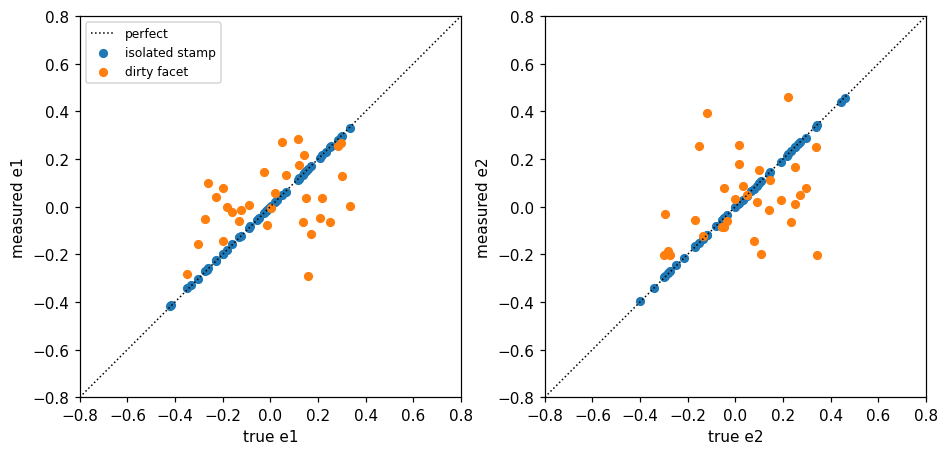

In [6]:
e_psf, _ = shape_galsim(psf)
e_dirty, ok_dirty = shape_galsim(dirty)

print(f"shape of the PSF itself (median over facets): e1={np.median(e_psf[:, 0]):+.2f}, e2={np.median(e_psf[:, 1]):+.2f}")
print(f"valid on dirty facets: {ok_dirty.sum()}/{len(ok_dirty)}   (noise makes the fit fail on some)")
print(f"median |measured - true| on dirty facets: {np.nanmedian(shape_error(e_dirty, ok_dirty)):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
for k, a in enumerate(ax):
    a.plot([-0.8, 0.8], [-0.8, 0.8], "k:", lw=1, label="perfect")
    a.scatter(e_true[:, k], e_iso[:, k], s=25, label="isolated stamp")
    a.scatter(e_true[ok_dirty, k], e_dirty[ok_dirty, k], s=25, label="dirty facet")
    a.set(xlabel=f"true e{k + 1}", ylabel=f"measured e{k + 1}", xlim=(-0.8, 0.8), ylim=(-0.8, 0.8), aspect="equal")
ax[0].legend(fontsize=8);

Measuring the dirty facets directly fails in three ways: the shapes are pulled towards the PSF's shape (the orange points
spread around the diagonal), noise scatters them, and some fits fail outright. Hence the next step:
**undo the blur first**.

## 3. Deconvolution with HQS-PnP

### Why it's hard: the naive inversion

Since dirty = galaxy ⊛ PSF + noise, and convolution becomes multiplication in Fourier space, the obvious fix is to divide:
galaxy = FFT⁻¹(FFT(dirty) / FFT(PSF)). The problem: wherever the telescope measured little (the gaps in the uv coverage), FFT(PSF)
is close to zero, and dividing by nearly zero blows the noise up enormously.

The standard fix is to add a small number α to the denominator,

$$x = \mathrm{FFT}^{-1}\left[\frac{\overline{\hat P}\,\hat D}{|\hat P|^2 + \alpha}\right]$$

(hats are Fourier transforms, $\overline{\hat P}$ the complex conjugate). Small α trusts the data and amplifies noise; large α
plays safe and stays blurry. That formula is exactly HQS-PnP's **data step** (`HQS_PnP.iteration_step`, called here with an empty
starting guess), so we can try a few α values on our target galaxy:

  niter=30, f1=0.380469, f2=3.70351, falpha=3.10972, SIGMA=7.1e-07


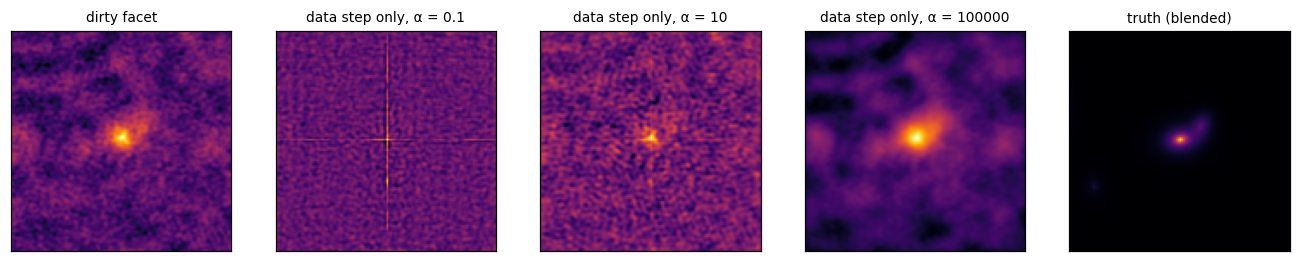

In [7]:
from deepshape2.models.hqs_pnp import create_model

hqs = create_model(device=DEVICE, path=WEIGHTS / "drunet_blended.pt")   # what reconstruct_facets builds internally

images = torch.tensor(np.stack([dirty, psf], axis=1), dtype=torch.float32)   # (n_galaxies, 2, 128, 128): [dirty, PSF]
one = images[i_target:i_target + 1].to(DEVICE)

# HQS pads to 256x256 so the FFT doesn't wrap galaxies around the edges
d_pad = hqs.pad_batch(one[:, :1])
fpsf = torch.fft.fft2(torch.fft.ifftshift(hqs.pad_batch(one[:, 1:]), dim=(-2, -1)))

alphas = [0.1, 10, 1e5]
fig, ax = plt.subplots(1, len(alphas) + 2, figsize=(15, 3.2))
show(ax[0], dirty[i_target], "dirty facet")
for a, alpha in zip(ax[1:], alphas):
    with torch.inference_mode():
        x = hqs.unpad_image(hqs.iteration_step(torch.zeros_like(d_pad), d_pad, fpsf, alpha))
    show(a, x[0, 0].cpu(), f"data step only, α = {alpha:g}")
show(ax[-1], blended[i_target], "truth (blended)")

Small α: noise everywhere (the streaks are where the uv coverage is thinnest). Huge α: back to a blurry image, even blurrier than
the dirty one. In between you get some of both. No single α works, because the data alone can't tell noise apart from real
fine structure. That needs **prior knowledge of what galaxies look like**, and that's where the neural network comes in.

### How HQS-PnP works

HQS ("half-quadratic splitting") with a PnP ("plug-and-play") denoiser alternates two steps, 30 times:

1. **Data step** (the formula above, now with the previous estimate z in it): find the image that best explains the dirty image,
   while staying close to z: $\hat x = (\overline{\hat P}\hat D + \alpha\,\hat z)\,/\,(|\hat P|^2 + \alpha)$.
2. **Denoising step**: z = DRUNet(x, σ). **DRUNet** is a neural network trained to remove noise of strength σ from an image.
   Fine-tuned on simulated galaxies (`drunet_blended.pt`), it has learned what galaxies look like, and so what counts as "noise".

Neither step knows about the other: the data step knows the physics (the PSF) and the denoiser knows galaxies. Alternating them
gives an image that is consistent with the data *and* looks like a galaxy.

The two knobs change every iteration, following a schedule set by 5 numbers in the config (`hqs_hyperparams`, tuned with Optuna
in `reconstruction/hyperparameter_tuning.py` for SKA-MID data):

* **σ** goes **down**: early on the estimate is very noisy, so the denoiser cleans hard; later it only touches up.
* **α** goes **up**: early on the data step may change the image a lot; later it makes only small careful changes.

hqs_hyperparams from the config: {'niter': 30, 'SIGMA': 7.1e-07, 'f1': 0.38046931731218053, 'f2': 3.7035096781994907, 'falpha': 3.1097160530212475}


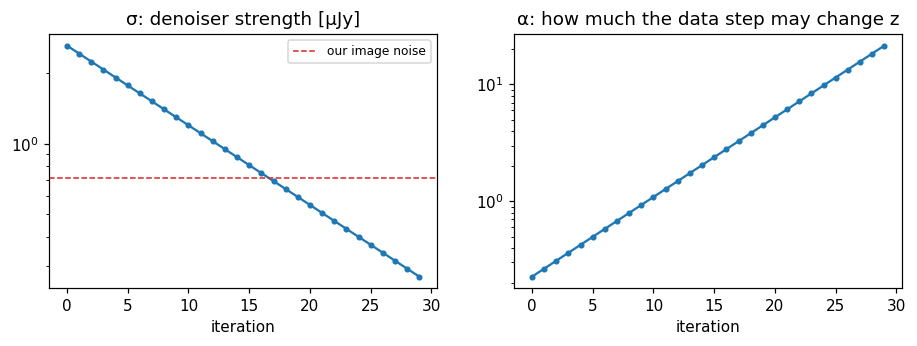

In [8]:
print("hqs_hyperparams from the config:", dict(cfg["hqs_hyperparams"]))

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].semilogy(hqs.sigma_k.cpu() * 1e6, "o-", ms=3)
ax[0].axhline(noise_rms * 1e6, color="C3", ls="--", lw=1, label="our image noise")
ax[0].set(title="σ: denoiser strength [µJy]", xlabel="iteration"); ax[0].legend(fontsize=8)
ax[1].semilogy(hqs.alpha_k.cpu(), "o-", ms=3)
ax[1].set(title="α: how much the data step may change z", xlabel="iteration");

### Watching it work

This loop is the body of `HQS_PnP.forward`, written out so we can save pictures along the way. The top row is the data step's
output, the bottom row the denoiser's.

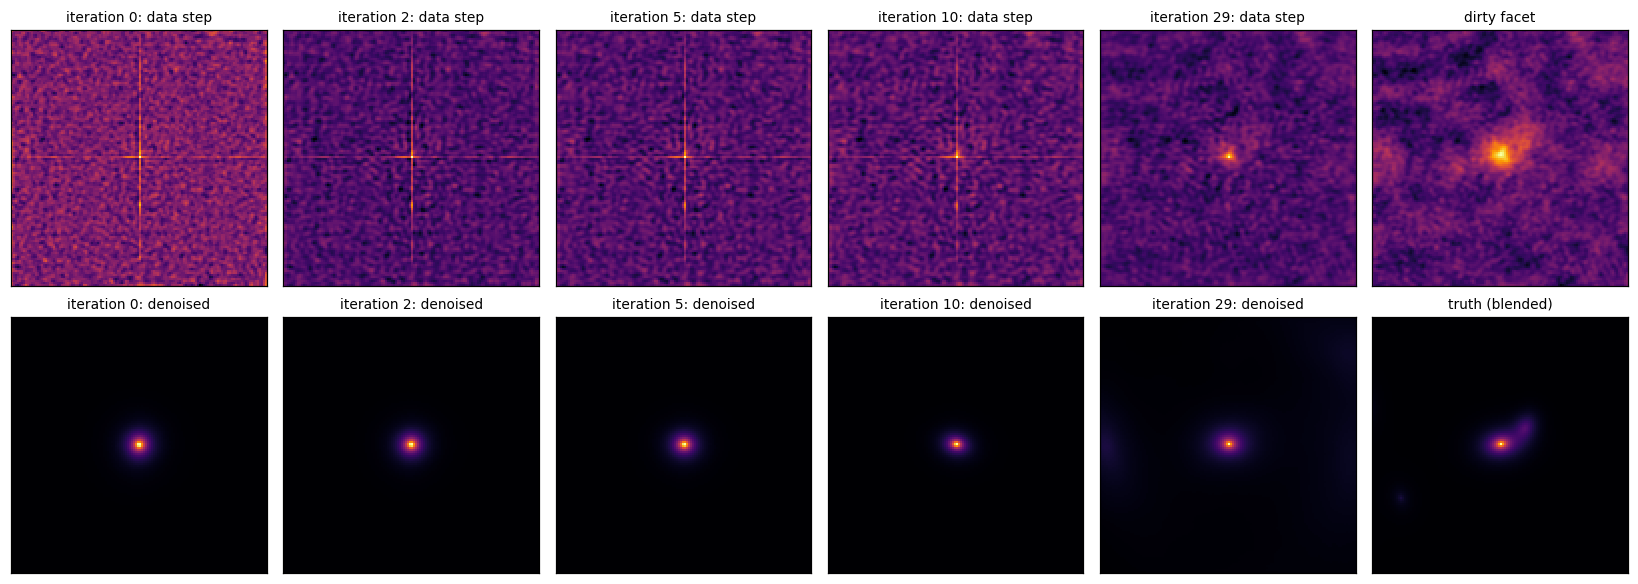

In [9]:
z = d_pad.clone()
snapshots = {}
with torch.inference_mode():
    for k, (alpha, sigma) in enumerate(zip(hqs.alpha_k, hqs.sigma_k)):
        x = hqs.unpad_image(hqs.iteration_step(z, d_pad, fpsf, alpha))   # 1. data step
        z_small = hqs.denoiser(x, sigma)                                 # 2. denoising step
        z = hqs.pad_batch(z_small)
        if k in (0, 2, 5, 10, 29):
            snapshots[k] = (x[0, 0].cpu(), z_small[0, 0].cpu())

fig, ax = plt.subplots(2, len(snapshots) + 1, figsize=(15, 5.5))
for col, (k, (x, zk)) in enumerate(snapshots.items()):
    show(ax[0, col], x, f"iteration {k}: data step")
    show(ax[1, col], zk, f"iteration {k}: denoised")
show(ax[0, -1], dirty[i_target], "dirty facet")
show(ax[1, -1], blended[i_target], "truth (blended)")
plt.tight_layout()

### All galaxies: `reconstruct_facets`

`reconstruct_facets` (in `deepshape2/reconstruction/main.py`) does the same for every facet in batches. Its arguments:

* `hqs_params={"path": ...}`: passed to `create_model`, to point it at our weights instead of the cluster's `MODEL_DIR`
  (other keys like `niter=` or `f1=` would override the config's hyperparameters)
* `do_chi2=True`: also return a data-consistency check (below)
* `num_workers=0`: load data in the main process, simplest for a small batch on a laptop

Without a deblender, the result's `"recon"` is the deconvolved image.

In [10]:
from deepshape2.reconstruction import reconstruct_facets

t = time.time()
result = reconstruct_facets(
    dirty, psf, device=DEVICE,
    hqs_params={"path": WEIGHTS / "drunet_blended.pt"},
    do_chi2=True, num_workers=0,
)
decon, chi2 = result["recon"], result["chi2"]
print(f"deconvolved {decon.shape} in {time.time() - t:.0f} s")

  niter=30, f1=0.380469, f2=3.70351, falpha=3.10972, SIGMA=7.1e-07


Reconstructing facets: 100%|###########################################################################################################################################| 1/1 [00:53<00:00, 53.92s/batch]

deconvolved (46, 128, 128) in 56 s


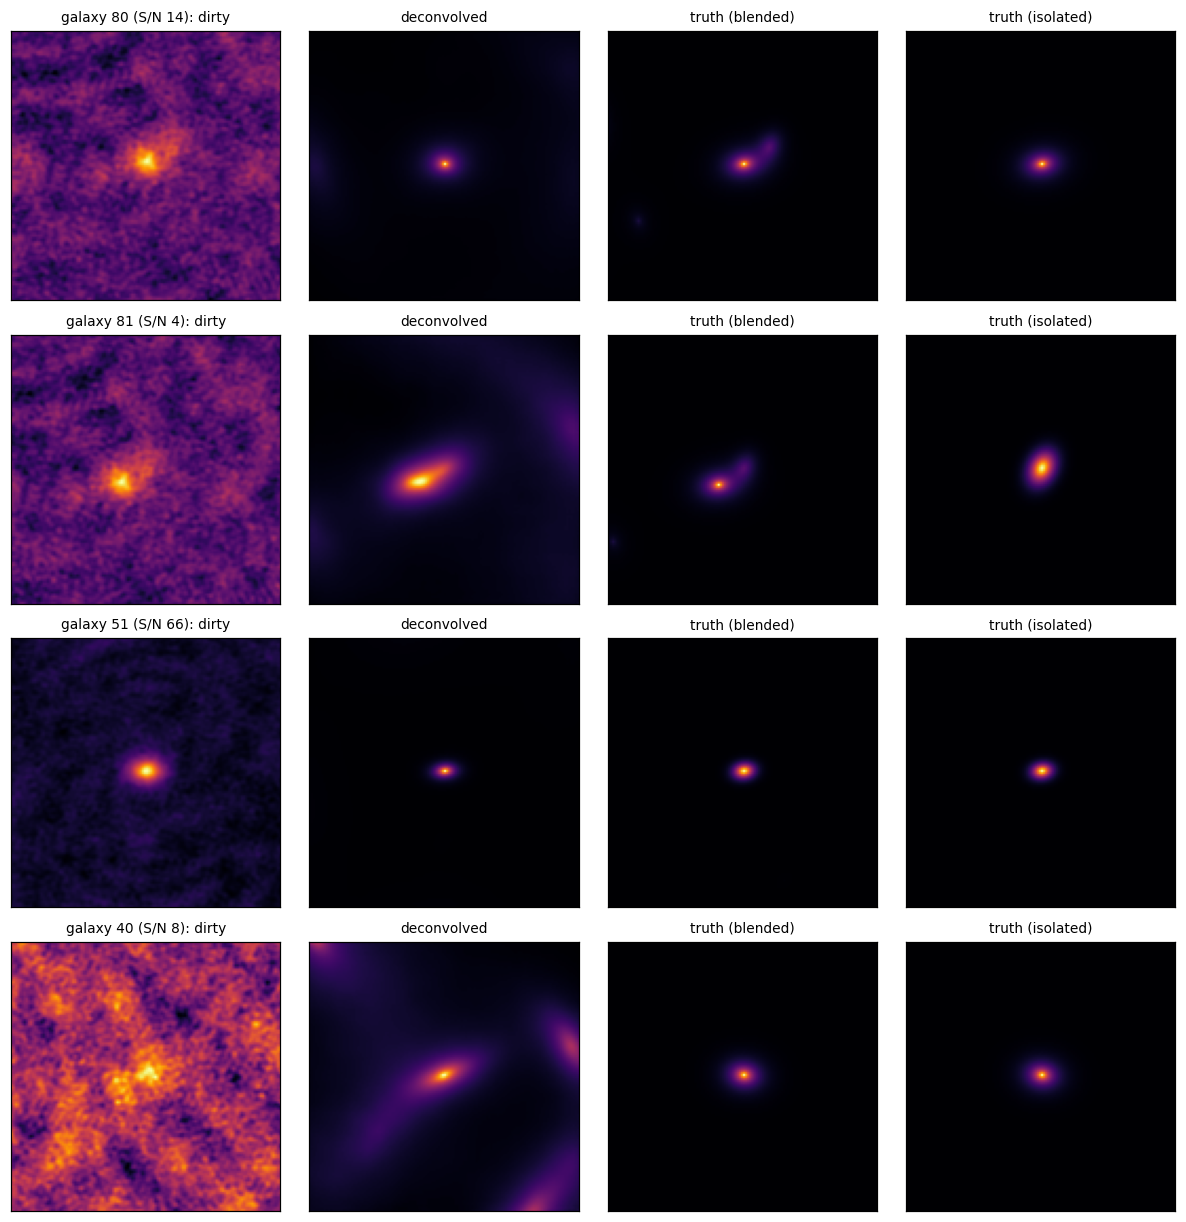

In [11]:
order = np.argsort(-gal["S/N"].values)
rows = [i_target, i_neighbour, order[0], order[len(order) // 2]]

fig, ax = plt.subplots(len(rows), 4, figsize=(11, 2.8 * len(rows)))
for r, i in enumerate(rows):
    show(ax[r, 0], dirty[i], f"galaxy {gal.index[i]} (S/N {gal['S/N'].iloc[i]:.0f}): dirty")
    show(ax[r, 1], decon[i], "deconvolved")
    show(ax[r, 2], blended[i], "truth (blended)")
    show(ax[r, 3], isolated[i], "truth (isolated)")
plt.tight_layout()

The bright galaxies come out sharp and close to the truth. Look at the faint ones (S/N below ~10), though: there the denoiser
has little to go on and partly **invents** a galaxy from noise patterns, sometimes with the wrong shape or extra blobs. That's
not a bug, it's what any method does near the noise level, and it's why results are judged only on a bright selection (section 5c).

### Did it work? Two checks

**χ² (data consistency).** Blur the reconstruction with the PSF again and compare with the dirty image (`chi2_dirty`, in
`utils/metrics.py`): χ² = mean of (difference / σ)², with σ = 0.71 µJy, the noise level the method was tuned for. If the reconstruction
explains everything except the noise, χ² ≈ 1. A value of 2–3 means a little real structure is left unexplained, which is fine.
Values in the hundreds mean failure: that's what we got when part 1 used settings the networks weren't trained on. Much smaller than 1
would mean the reconstruction is copying the noise.

**PSNR (closeness to the truth).** Peak signal-to-noise ratio, `psnr_batch` = 10·log₁₀(peak² / mean squared error), in decibels.
Every +10 dB is 10× smaller squared error; 40 dB means the typical error is about 1% of the galaxy's peak. We compare against the
**blended** truth, because deconvolution removes the blur but not the neighbours.

In [12]:
from deepshape2.utils import psnr_batch

psnr_decon = psnr_batch(blended, decon)
print(f"χ²   : median {np.median(chi2):.2f}, range {chi2.min():.2f} – {chi2.max():.2f}")
print(f"PSNR : median {np.median(psnr_decon):.1f} dB vs blended truth "
      f"({np.median(psnr_decon[selected]):.1f} dB for the selected bright galaxies)")

χ²   : median 2.01, range 1.44 – 3.00
PSNR : median 28.9 dB vs blended truth (35.8 dB for the selected bright galaxies)


## 4. Deblending with the VAE

### Why

The deconvolved target facet still contains its neighbour, and a shape measurement there sees both galaxies. **Blendedness**
(`blendedness` in `utils/metrics.py`) puts a number on how bad it is, from the isolated stamp *t* and the blended stamp *b*:

$$\text{blendedness} = 1 - \frac{\sum t \cdot t}{\sum b \cdot t}$$

If nothing else is there, *b = t* and blendedness is 0. The more neighbour light sits *on top of the galaxy* (the sums are
weighted by the galaxy's own profile), the closer it gets to 1.

In [13]:
from deepshape2.utils import blendedness

gal["blendedness"] = blendedness(isolated, blended)
gal["selected"] = selected
gal.sort_values("blendedness", ascending=False).head(6)[["flux [µJy]", "S/N", "selected", "blendedness"]].round(3)

,flux [µJy],S/N,selected,blendedness
81,20.000,4.378,False,0.402
8,10.503,1.575,False,0.117
80,80.000,14.213,True,0.068
53,86.855,10.242,True,0.066
33,82.756,10.540,True,0.064
71,36.244,6.473,False,0.043


### What the VAE is

A **VAE** (variational autoencoder, `models/vae.py`) has two halves. The **encoder** squeezes the 128×128 image down to 16
numbers, and the **decoder** builds a 128×128 image back from them. 16 numbers are enough to describe one smooth galaxy, but not
"a galaxy plus whatever is next to it". It was trained (`deblending/training.py`) on pairs of input = blended stamp and
target = isolated stamp, so it learned to keep the central galaxy and drop the rest. "Variational" means the 16 numbers carry a
little built-in randomness, so the output varies very slightly from run to run; fixing the random seed makes it repeatable.

### The arcsinh trick again

Inside `reconstruct_facets`, the deblender is applied like this:

```python
decon_scaled = torch.arcsinh_(decon_crop.mul_(SCALE_FACTOR))   # SCALE_FACTOR = 5e7, from the config
decon_deblended = deblender(decon_scaled)[0]
recon = torch.sinh_(decon_deblended).div_(SCALE_FACTOR)         # undo the scaling
```

It's the same arcsinh stretch we used for plotting, now applied to the data. A galaxy's bright core and its faint outskirts differ
by a factor of 100 or more. Without the stretch, the network's training would care almost only about the core; with it, the
outskirts, which carry much of the shape information, count too. `sinh` turns the output back into Jy/pixel.

In [14]:
from deepshape2.utils import load_model

vae = load_model("deblender", DEVICE, path=WEIGHTS / "vae_mha.pt", cfg=cfg)

torch.manual_seed(0)   # the VAE's built-in randomness, made repeatable
t = time.time()
result = reconstruct_facets(
    dirty, psf, device=DEVICE,
    hqs_params={"path": WEIGHTS / "drunet_blended.pt"},
    deblender=vae, num_workers=0,
)
recon = result["recon"]          # deconvolved AND deblended
print(f"done in {time.time() - t:.0f} s;  result['decon'] is the same deconvolution as before, before deblending")

Loading deblender (VAE) from ../deepshape2/DS2_model_weights/vae_mha.pt (user path)
  niter=30, f1=0.380469, f2=3.70351, falpha=3.10972, SIGMA=7.1e-07


Reconstructing facets: 100%|###########################################################################################################################################| 1/1 [00:57<00:00, 57.47s/batch]

done in 59 s;  result['decon'] is the same deconvolution as before, before deblending


PSNR against the ISOLATED truth, before and after deblending:


,blendedness,PSNR decon,PSNR deblended
80,0.07,28.150000,39.470001
53,0.07,24.530001,32.759998
33,0.06,24.600000,36.950001


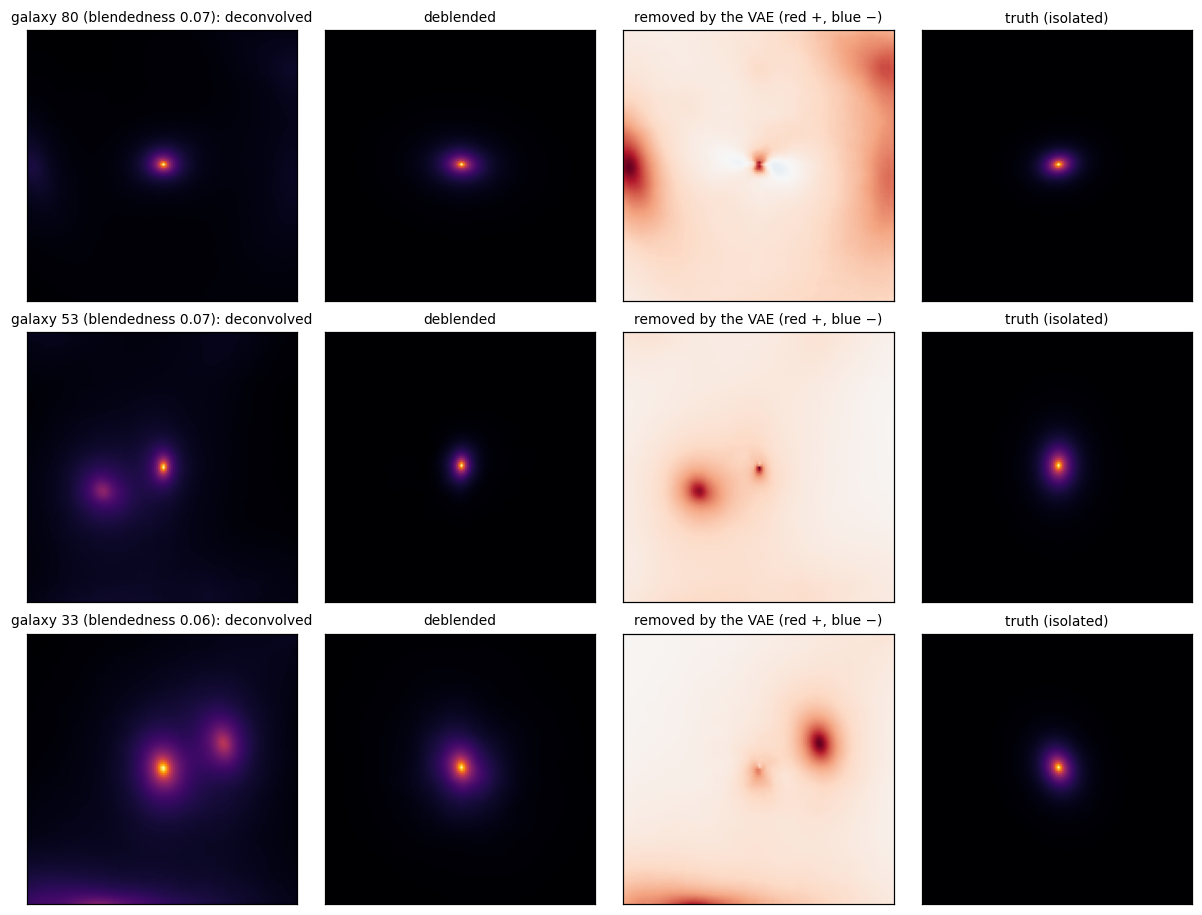

In [18]:
candidates = np.where(selected)[0]   # most blended among the galaxies bright enough to measure
most_blended = candidates[np.argsort(-gal["blendedness"].values[candidates])[:3]]

fig, ax = plt.subplots(len(most_blended), 4, figsize=(11, 2.8 * len(most_blended)))
for r, i in enumerate(most_blended):
    show(ax[r, 0], decon[i], f"galaxy {gal.index[i]} (blendedness {gal['blendedness'].iloc[i]:.2f}): deconvolved")
    show(ax[r, 1], recon[i], "deblended")
    removed = decon[i] - recon[i]
    lim = np.abs(removed).max()
    show(ax[r, 2], removed, "removed by the VAE (red +, blue −)", cmap="RdBu_r", vmin=-lim, vmax=lim)
    show(ax[r, 3], isolated[i], "truth (isolated)")
plt.tight_layout()

gal["PSNR decon"] = psnr_batch(isolated, decon)
gal["PSNR deblended"] = psnr_batch(isolated, recon)
print("PSNR against the ISOLATED truth, before and after deblending:")
gal.iloc[most_blended][["blendedness", "PSNR decon", "PSNR deblended"]].round(2)

For the blended galaxies, deblending should raise the PSNR against the isolated truth. For isolated galaxies there's nothing to
remove, and the VAE should leave them roughly as they were. (Have a look at the faintest, most blended galaxies too, for example our
deliberate neighbour from part 1: when the galaxy is barely above the noise and a brighter one sits next to it, the VAE can keep
the wrong one.)

## 5. Shape measurement

### 5a. The ruler on the reconstructions

First the classical measurement again, on the deconvolved images and on the deconvolved + deblended ones.

In [19]:
e_decon, ok_decon = shape_galsim(decon)
e_recon, ok_recon = shape_galsim(recon)
for name, err in [("deconvolved", shape_error(e_decon, ok_decon)), ("deconvolved + deblended", shape_error(e_recon, ok_recon))]:
    print(f"{name:25s} median shape error: all {np.nanmedian(err):.3f}, selected {np.nanmedian(err[selected]):.3f}")

deconvolved               median shape error: all 0.244, selected 0.161
deconvolved + deblended   median shape error: all 0.301, selected 0.147


### 5b. The shape network: `shapenet_full`

Even after deconvolution, some effect of the PSF and the noise remains in the image, and adaptive moments can't correct for it.
DeepShape2 therefore trains a network to go straight from (reconstruction, PSF) to (e1, e2) (`models/shape_network.py`). It has
two branches:

* **Image branch**: an **E(2)-equivariant CNN** (built with the `escnn` library, weights `eq_block.pt`). An ordinary CNN has to
  learn from examples that a rotated galaxy is the same galaxy rotated. This one is built so that rotating or flipping the input
  transforms its internal features in a fixed, known way, so it handles every orientation equally by construction. That suits a
  quantity like ellipticity, which has a direction.
* **PSF branch**: the encoder half of a **PSF autoencoder** (`autoencoder_jit.pt`), trained separately to compress a PSF into
  1152 numbers. These tell the network what blur it is looking through.

A small fully connected network combines the two and outputs (e1, e2), squeezed into (−1, 1) by a tanh. It was trained in
`shape_measurement/training_full.py` on many simulated (reconstruction, PSF) pairs with the catalogue shapes as targets.

`load_model` builds it from the `shapenet` entry in the config; its two sub-networks also default to the cluster's paths, so we
pass ours via `args_override`. `predict_shape` (in `shape_measurement/main.py`) rescales each image and PSF to the range 0–1
first: the network should judge shape, not brightness.

In [20]:
from deepshape2.shape_measurement import predict_shape

shapenet = load_model(
    "shapenet",
    path=WEIGHTS / "shape_network_full.pt",
    cfg=cfg,
    args_override={"encoder_path": WEIGHTS / "autoencoder_jit.pt", "eq_path": WEIGHTS / "eq_block.pt"},
)
e_net = predict_shape(recon, psf, shapenet, device="cpu", tqdm_enabled=False)
print(f"median shape error, network on reconstructions: {np.nanmedian(shape_error(e_net)):.3f}")

Loading shapenet (shapenet_full) from ../deepshape2/DS2_model_weights/shape_network_full.pt (user path)
median shape error, network on reconstructions: 0.246


### 5c. Comparing all the methods

`scripts/implementation/shape_measurement.py` judges results only on galaxies with **flux > 50 µJy** and a dirty-image **peak
above 3σ** (σ = 0.71 µJy). Below that the signal is simply too weak for anyone to measure a shape, and the network was trained only on
galaxies above 50 µJy. We report both: all galaxies, and that selection.

In [21]:
print(f"{selected.sum()} of {len(gal)} galaxies pass the selection\n")

methods = {
    "moments on isolated truth (best possible)": (e_iso, ok_iso),
    "moments on dirty facet": (e_dirty, ok_dirty),
    "moments on deconvolved": (e_decon, ok_decon),
    "moments on deconvolved + deblended": (e_recon, ok_recon),
    "shapenet on deconvolved + deblended": (e_net, np.ones(len(gal), bool)),
}
rows = []
for name, (e_meas, ok) in methods.items():
    err = shape_error(e_meas, ok)
    rows.append({
        "method": name,
        "valid": f"{ok.sum()}/{len(ok)}",
        "median error, all": np.nanmedian(err),
        "median error, selected": np.nanmedian(err[selected]),
    })
pd.DataFrame(rows).set_index("method").round(3)

20 of 46 galaxies pass the selection



,valid,"median error, all","median error, selected"
method,,,
moments on isolated truth (best possible),46/46,0.002,0.003
moments on dirty facet,32/46,0.227,0.219
moments on deconvolved,31/46,0.244,0.161
moments on deconvolved + deblended,46/46,0.301,0.147
shapenet on deconvolved + deblended,46/46,0.246,0.123


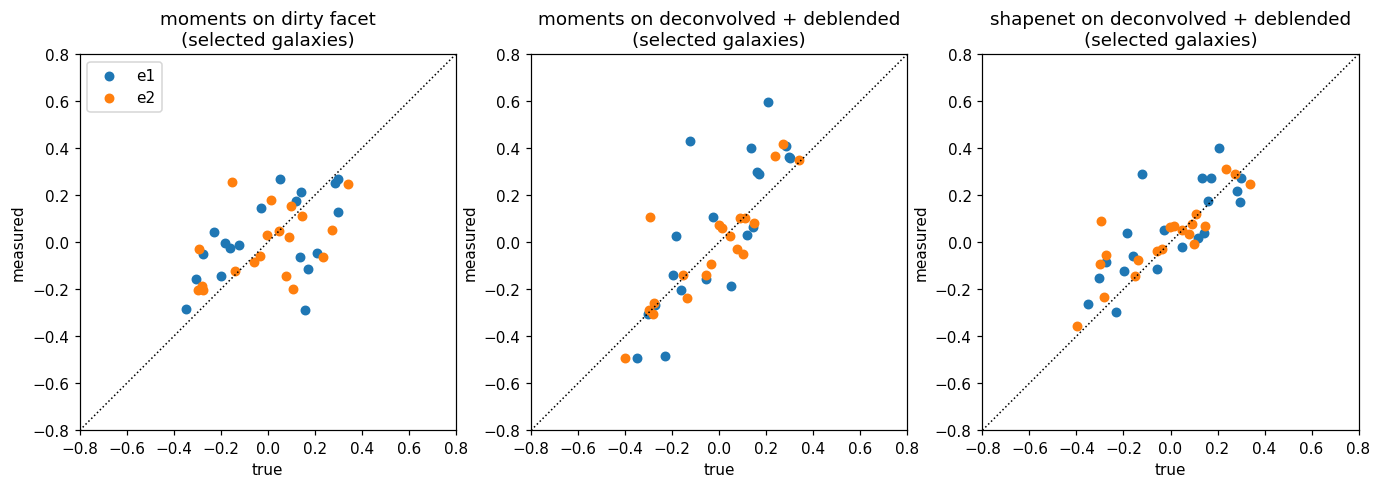

In [18]:
panels = [("moments on dirty facet", e_dirty, ok_dirty),
          ("moments on deconvolved + deblended", e_recon, ok_recon),
          ("shapenet on deconvolved + deblended", e_net, np.ones(len(gal), bool))]

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, (title, e_meas, ok) in zip(ax, panels):
    m = selected & ok
    a.plot([-0.8, 0.8], [-0.8, 0.8], "k:", lw=1)
    a.scatter(e_true[m, 0], e_meas[m, 0], s=30, label="e1")
    a.scatter(e_true[m, 1], e_meas[m, 1], s=30, label="e2")
    a.set(title=f"{title}\n(selected galaxies)", xlabel="true", ylabel="measured",
          xlim=(-0.8, 0.8), ylim=(-0.8, 0.8), aspect="equal")
ax[0].legend();

Careful with the "all" column: moments **fail** on many faint dirty facets and those are simply skipped, while on the
reconstructions every fit succeeds, so the hardest, faintest galaxies count there and drag the number up. That's one more reason to
compare on the selection.

The closer the points sit to the dotted diagonal, the better. With only a few dozen galaxies these numbers jump around from one
simulated sky to the next, so look at the trend rather than the exact values. The real evaluation uses tens of thousands of galaxies
and also checks for **bias** (`plot_bias` in `visualization/`): whether the measured shapes are systematically too large, too small,
or rotated. As section 1 said, for lensing that matters more than the scatter.

### 5d. Checking the built-in rotation behaviour

Rotate an image by 90° and its ellipse turns by 90°, so 2θ changes by 180°, and **both e1 and e2 flip sign**. The image branch is built
to handle rotations, but the PSF branch and the final layers aren't, so the whole network only follows this rule
**approximately**: expect the signs to flip for most galaxies, with the numbers only roughly matching.

In [22]:
def rot90(images):
    return np.rot90(images, k=1, axes=(1, 2)).copy()

e_net_rot = predict_shape(rot90(recon), rot90(psf), shapenet, device="cpu", tqdm_enabled=False)

for i in order[:5]:
    print(f"galaxy {gal.index[i]:3d}: prediction {np.round(e_net[i], 3)}   after rotating 90° {np.round(e_net_rot[i], 3)}")

galaxy  51: prediction [0.169 0.079]   after rotating 90° [-0.13  -0.028]
galaxy  26: prediction [-0.083 -0.03 ]   after rotating 90° [0.15  0.049]
galaxy  78: prediction [0.053 0.063]   after rotating 90° [0.024 0.022]
galaxy   7: prediction [-0.061 -0.076]   after rotating 90° [0.123 0.105]
galaxy  18: prediction [ 0.019 -0.091]   after rotating 90° [0.037 0.157]


## Recap

```
dirty facet + PSF ──HQS-PnP──> deconvolved ──VAE──> deblended ──shapenet──> (e1, e2)
   (part 1)        physics step +            removes          equivariant CNN
                   DRUNet denoiser,           neighbours       + PSF encoder
                   30 iterations
```

| Step | Why it's needed | How we checked it |
|---|---|---|
| Deconvolution (HQS-PnP) | the PSF drags every shape towards its own; noise scatters them | χ² ≈ 1, PSNR vs blended truth |
| Deblending (VAE) | neighbours' light contaminates the target | blendedness, PSNR vs isolated truth |
| Shape network | moments can't correct the leftover PSF and noise effects | shape error vs catalogue, on the paper's selection |

### Things to try
* Change HQS's hyperparameters, e.g. `hqs_params={"path": ..., "niter": 5}` or a different `f1`, and watch χ², PSNR and the shapes.
* Run `predict_shape` on the **deconvolved** images (skipping the deblender) and see how much deblending helps the network.
* In part 1, move the neighbour closer to the target or make it brighter, re-run part 1 to the end, then re-run this notebook.
* In part 1, go back to the config's LOFAR settings and re-run both: the networks were never trained on that, and you'll see them fail.
  That's a useful reminder that a trained network is only as good as the match between its training data and your data.